# Employee Data Analysis — Week 1 Assessment

## Project Objective
Analyse employee data using NumPy, Pandas and Matplotlib.

## Objectives
- Load and explore employee data.
- Handle missing values and duplicate records.
- Analyse department-wise salaries and headcount.
- Merge employee and department datasets.
- Visualise employee salary patterns.

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("Libraries imported successfully")

Libraries imported successfully


## 1. Load Employee Dataset
Load the employee dataset and display the first five records.

In [19]:
root = Path.cwd()

if not (root / "data").exists():
    root = root.parent

df = pd.read_csv(root / "data" / "employees.csv")

df.head()

,id,name,department,salary,city
0,1,Arun,Sales,30000,Chennai
1,2,Priya,HR,45000,Chennai
2,3,Rahul,IT,60000,Bangalore
3,4,Divya,IT,75000,Chennai
4,5,Karthik,Finance,90000,Mumbai


## 2. Data Exploration
Examine the dataset structure, data types, missing values
and duplicate records.

In [20]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nSummary Statistics:")
print(df.describe())

print("\nMissing Values:")
print(df.isna().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Shape: (8, 5)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id          8 non-null      int64
 1   name        8 non-null      str  
 2   department  8 non-null      str  
 3   salary      8 non-null      int64
 4   city        8 non-null      str  
dtypes: int64(2), str(3)
memory usage: 452.0 bytes

Summary Statistics:
            id        salary
count  8.00000      8.000000
mean   4.50000  58500.000000
std    2.44949  18913.336187
min    1.00000  30000.000000
25%    2.75000  47250.000000
50%    4.50000  56000.000000
75%    6.25000  69750.000000
max    8.00000  90000.000000

Missing Values:
id            0
name          0
department    0
salary        0
city          0
dtype: int64

Duplicate Records:
0


## 3. Performance Measurement
Use the Jupyter %timeit magic command to measure
the execution time of a salary calculation.

In [21]:
%timeit df["salary"].mean()

38.5 μs ± 1.26 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


## 4. NumPy Array Analysis

Analyse student marks using NumPy arrays, averages,
broadcasting and weighted scores.

In [22]:
marks = np.array([
    [75, 80, 85],
    [65, 70, 75],
    [90, 85, 95],
    [60, 75, 80]
])

print("Marks:\n", marks)
print("Shape:", marks.shape)
print("Student Averages:", marks.mean(axis=1))
print("Subject Averages:", marks.mean(axis=0))

print("\nAfter Adding 5 Grace Marks:")
print(marks + 5)

weights = np.array([0.3, 0.3, 0.4])

print("\nWeighted Scores:")
print(np.dot(marks, weights))

Marks:
 [[75 80 85]
 [65 70 75]
 [90 85 95]
 [60 75 80]]
Shape: (4, 3)
Student Averages: [80.         70.         90.         71.66666667]
Subject Averages: [72.5  77.5  83.75]

After Adding 5 Grace Marks:
[[ 80  85  90]
 [ 70  75  80]
 [ 95  90 100]
 [ 65  80  85]]

Weighted Scores:
[80.5 70.5 90.5 72.5]


## 5. Data Cleaning

- Identify missing values.
- Fill missing salaries using the median.
- Remove duplicate records.
- Correct data types.
- Standardise text values.

In [23]:
df_missing = pd.read_csv(
    root / "data" / "employees_missing.csv"
)

print("Before Cleaning:")
print("Shape:", df_missing.shape)

print("\nMissing Values:")
print(df_missing.isna().sum())

print("\nDuplicate Records:")
print(df_missing.duplicated().sum())

df_missing.head()

Before Cleaning:
Shape: (11, 5)

Missing Values:
id            0
name          0
department    0
salary        2
city          0
dtype: int64

Duplicate Records:
1


,id,name,department,salary,city
0,1,Arun,Sales,30000.0,Chennai
1,2,Priya,HR,45000.0,Chennai
2,3,Rahul,IT,60000.0,Bangalore
3,4,Divya,IT,75000.0,Chennai
4,5,Karthik,Finance,90000.0,Mumbai


In [24]:
df_clean = df_missing.copy()

# Convert salary to numeric
df_clean["salary"] = pd.to_numeric(
    df_clean["salary"], errors="coerce"
)

# Fill missing salaries with median
median_salary = df_clean["salary"].median()

df_clean["salary"] = df_clean["salary"].fillna(
    median_salary
)

# Standardise text columns
for col in ["name", "department", "city"]:
    df_clean[col] = df_clean[col].str.strip().str.title()

# Remove duplicate records
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Data Cleaning Completed")
print("Median Salary:", median_salary)

df_clean

Data Cleaning Completed
Median Salary: 55000.0


,id,name,department,salary,city
0,1,Arun,Sales,30000.0,Chennai
1,2,Priya,Hr,45000.0,Chennai
2,3,Rahul,It,60000.0,Bangalore
3,4,Divya,It,75000.0,Chennai
4,5,Karthik,Finance,90000.0,Mumbai
5,6,Meena,Sales,55000.0,Bangalore
6,7,Suresh,It,68000.0,Chennai
7,8,Anitha,Hr,48000.0,Mumbai
8,9,Ravi,Finance,55000.0,Chennai
9,10,Pooja,Sales,55000.0,Bangalore


In [25]:
print("After Cleaning:")
print("Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isna().sum())

print("\nDuplicate Records:")
print(df_clean.duplicated().sum())

After Cleaning:
Shape: (10, 5)

Missing Values:
id            0
name          0
department    0
salary        0
city          0
dtype: int64

Duplicate Records:
0


## 6. Department-wise Analysis

Calculate employee headcount, average salary and maximum
salary for each department using groupby and aggregation.

In [26]:
# Standardise department names
df_clean["department"] = df_clean["department"].str.upper()

department_summary = df_clean.groupby("department").agg(
    headcount=("id", "count"),
    average_salary=("salary", "mean"),
    maximum_salary=("salary", "max")
).reset_index()

department_summary

,department,headcount,average_salary,maximum_salary
0,FINANCE,2,72500.000000,90000.0
1,HR,2,46500.000000,48000.0
2,IT,3,67666.666667,75000.0
3,SALES,3,46666.666667,55000.0


## 7. Dataset Merging

Combine employee and department datasets using inner,
left and outer joins.

Identify departments that have no employees.

In [27]:
departments = pd.read_csv(
    root / "data" / "departments.csv"
)

departments["department"] = (
    departments["department"].str.strip().str.upper()
)

departments

,department,bonus,head,budget
0,SALES,5000,Vikram,500000
1,HR,3000,Neha,400000
2,IT,8000,Ramesh,1000000
3,FINANCE,6000,Sneha,750000
4,MARKETING,7000,Amit,600000


In [28]:
inner_join = pd.merge(
    df_clean,
    departments,
    on="department",
    how="inner"
)

print("Inner Join:")
inner_join

Inner Join:


,id,name,department,salary,city,bonus,head,budget
0,1,Arun,SALES,30000.0,Chennai,5000,Vikram,500000
1,2,Priya,HR,45000.0,Chennai,3000,Neha,400000
2,3,Rahul,IT,60000.0,Bangalore,8000,Ramesh,1000000
3,4,Divya,IT,75000.0,Chennai,8000,Ramesh,1000000
4,5,Karthik,FINANCE,90000.0,Mumbai,6000,Sneha,750000
5,6,Meena,SALES,55000.0,Bangalore,5000,Vikram,500000
6,7,Suresh,IT,68000.0,Chennai,8000,Ramesh,1000000
7,8,Anitha,HR,48000.0,Mumbai,3000,Neha,400000
8,9,Ravi,FINANCE,55000.0,Chennai,6000,Sneha,750000
9,10,Pooja,SALES,55000.0,Bangalore,5000,Vikram,500000


In [29]:
left_join = pd.merge(
    df_clean,
    departments,
    on="department",
    how="left"
)

print("Left Join:")
left_join

Left Join:


,id,name,department,salary,city,bonus,head,budget
0,1,Arun,SALES,30000.0,Chennai,5000,Vikram,500000
1,2,Priya,HR,45000.0,Chennai,3000,Neha,400000
2,3,Rahul,IT,60000.0,Bangalore,8000,Ramesh,1000000
3,4,Divya,IT,75000.0,Chennai,8000,Ramesh,1000000
4,5,Karthik,FINANCE,90000.0,Mumbai,6000,Sneha,750000
5,6,Meena,SALES,55000.0,Bangalore,5000,Vikram,500000
6,7,Suresh,IT,68000.0,Chennai,8000,Ramesh,1000000
7,8,Anitha,HR,48000.0,Mumbai,3000,Neha,400000
8,9,Ravi,FINANCE,55000.0,Chennai,6000,Sneha,750000
9,10,Pooja,SALES,55000.0,Bangalore,5000,Vikram,500000


In [30]:
outer_join = pd.merge(
    df_clean,
    departments,
    on="department",
    how="outer",
    indicator=True
)

print("Outer Join:")
outer_join

Outer Join:


,id,name,department,salary,city,bonus,head,budget,_merge
0,5.0,Karthik,FINANCE,90000.0,Mumbai,6000,Sneha,750000,both
1,9.0,Ravi,FINANCE,55000.0,Chennai,6000,Sneha,750000,both
2,2.0,Priya,HR,45000.0,Chennai,3000,Neha,400000,both
3,8.0,Anitha,HR,48000.0,Mumbai,3000,Neha,400000,both
4,3.0,Rahul,IT,60000.0,Bangalore,8000,Ramesh,1000000,both
5,4.0,Divya,IT,75000.0,Chennai,8000,Ramesh,1000000,both
6,7.0,Suresh,IT,68000.0,Chennai,8000,Ramesh,1000000,both
7,NaN,NaN,MARKETING,NaN,NaN,7000,Amit,600000,right_only
8,1.0,Arun,SALES,30000.0,Chennai,5000,Vikram,500000,both
9,6.0,Meena,SALES,55000.0,Bangalore,5000,Vikram,500000,both


In [31]:
no_employees = outer_join.loc[
    outer_join["_merge"] == "right_only",
    ["department", "head", "budget", "bonus"]
]

print("Departments with no employees:")
print(no_employees.to_string(index=False))

Departments with no employees:
department head  budget  bonus
 MARKETING Amit  600000   7000


In [32]:
print(departments.columns.tolist())
print(outer_join.columns.tolist())

['department', 'bonus', 'head', 'budget']
['id', 'name', 'department', 'salary', 'city', 'bonus', 'head', 'budget', '_merge']


## 8. Data Visualisation

Visualise employee salary distribution, department-wise
average salaries and salary patterns using Matplotlib.

In [33]:
charts_path = root / "reports" / "charts"
charts_path.mkdir(parents=True, exist_ok=True)

plt.style.use("ggplot")

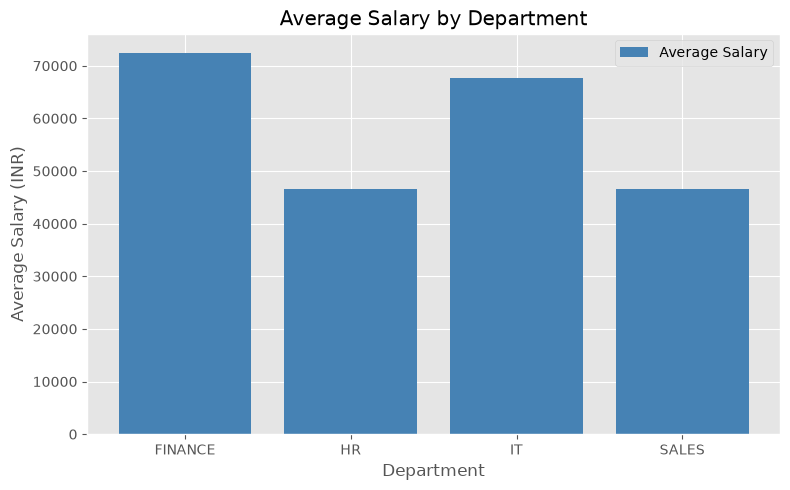

In [34]:
plt.figure(figsize=(8, 5))

plt.bar(
    department_summary["department"],
    department_summary["average_salary"],
    color="steelblue",
    label="Average Salary"
)

plt.title("Average Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average Salary (INR)")
plt.legend()
plt.tight_layout()

plt.savefig(charts_path / "department_salary_bar.png")
plt.show()

**Insight:** The bar chart helps identify which department
has the highest and lowest average salary.

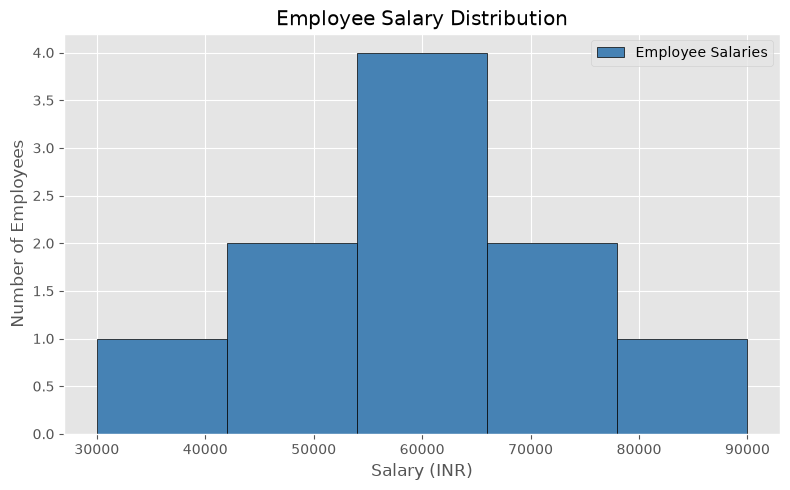

In [35]:
plt.figure(figsize=(8, 5))

plt.hist(
    df_clean["salary"],
    bins=5,
    color="steelblue",
    edgecolor="black",
    label="Employee Salaries"
)

plt.title("Employee Salary Distribution")
plt.xlabel("Salary (INR)")
plt.ylabel("Number of Employees")
plt.legend()
plt.tight_layout()

plt.savefig(charts_path / "salary_histogram.png")
plt.show()

**Insight:** The histogram shows how employee salaries
are distributed across different salary ranges.

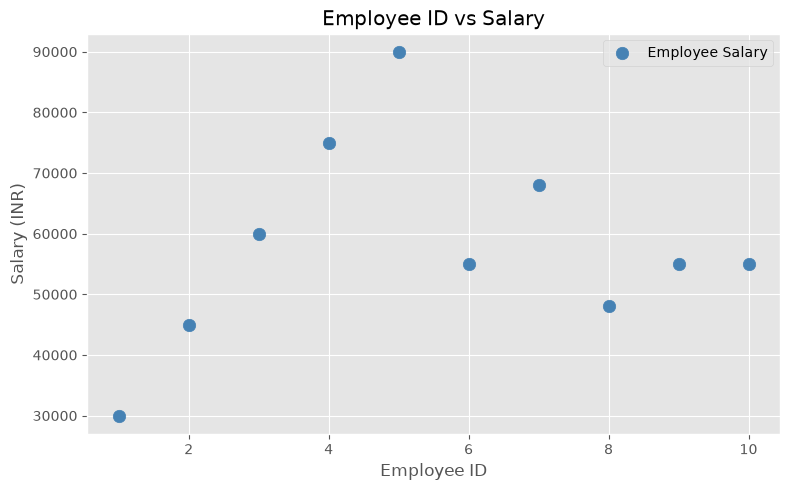

In [36]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean["id"],
    df_clean["salary"],
    color="steelblue",
    s=80,
    label="Employee Salary"
)

plt.title("Employee ID vs Salary")
plt.xlabel("Employee ID")
plt.ylabel("Salary (INR)")
plt.legend()
plt.tight_layout()

plt.savefig(charts_path / "salary_scatter.png")
plt.show()

**Insight:** The scatter plot highlights differences
in salary among individual employees.

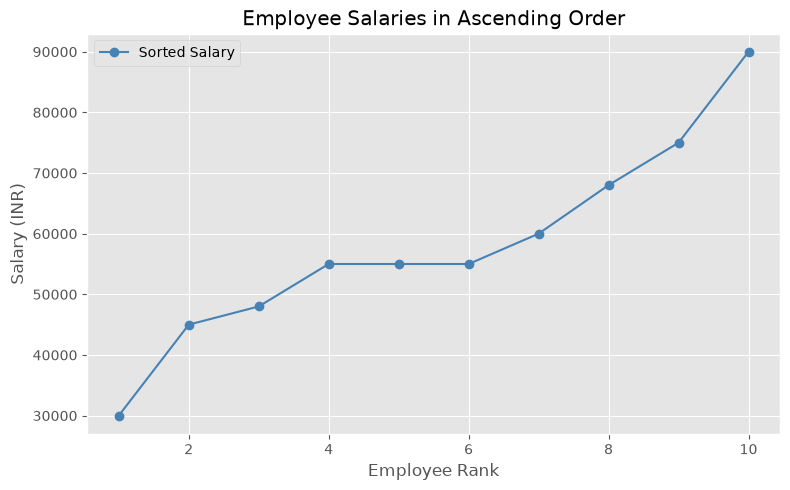

In [37]:
sorted_salary = df_clean["salary"].sort_values().reset_index(drop=True)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(sorted_salary) + 1),
    sorted_salary,
    marker="o",
    color="steelblue",
    label="Sorted Salary"
)

plt.title("Employee Salaries in Ascending Order")
plt.xlabel("Employee Rank")
plt.ylabel("Salary (INR)")
plt.legend()
plt.tight_layout()

plt.savefig(charts_path / "salary_line.png")
plt.show()

**Insight:** The line chart shows the salary gap
between the lowest-paid and highest-paid employees.